# Kryptografia kodów korekcyjnych

**Kryptografia postkwantowa — laboratorium** (PQC26)

Notebook jest napisany w języku **SageMath**. Aby go uruchomić, wybierz jądro (kernel) *SageMath* w Jupyterze. Komórki uruchamiamy po kolei, od góry do dołu (`Shift + Enter`).

### Plan notebooka

0. **SageMath — pierwsze kroki**
1. **Kody korekcyjne — co to jest i do czego służą** (w tym kod Hamminga)
2. **Kryptosystemy McEliece'a i Niederreitera (na kodzie Hamminga)**
3. **Kryptosystem McEliece'a na kodach Goppy**
4. **Mechanizm enkapsulacji klucza (KEM) na podstawie Niederreitera**
5. **Ataki na kryptosystemy kodów korekcyjnych**

### Co trzeba wiedzieć na start?

Wystarczy wiedzieć, czym jest **macierz** i **wektor** oraz jak się je **dodaje** i **mnoży**. Jak robi się to w Sage, pokazujemy w części 0; wszystko inne wprowadzimy po drodze.

---
# Część 0. SageMath — pierwsze kroki

## 1. Co to jest SageMath?

**SageMath** (krócej: **Sage**) to darmowy system obliczeń matematycznych o otwartym kodzie źródłowym, oparty na Pythonie. Dla nas najważniejsze jest to, że ma gotowe **ciała skończone**, **algebrę liniową** nad dowolnym ciałem (wektory, macierze, układy równań) oraz moduł teorii kodowania `codes`.

Sage można uruchomić lokalnie (jądro *SageMath* w Jupyterze) albo w przeglądarce: [SageMathCell](https://sagecell.sagemath.org), [CoCalc](https://cocalc.com).

**Pomoc:** `nazwa?` wyświetla dokumentację (np. `GF?`), `nazwa??` kod źródłowy, a `obiekt.` + `Tab` listę dostępnych metod.

## 2. Sage to Python z kilkoma dodatkami

Programy w Sage piszemy w **Pythonie**: działają zmienne, listy, pętle, funkcje i f-stringi. Sage zmienia jednak znaczenie kilku zapisów:

| zapis | w Pythonie | w Sage |
|:-:|---|---|
| `2^10` | XOR bitowy (`8`) | **potęga** (`1024`) |
| `5 ^^ 3` | błąd składni | **XOR bitowy** (`6`) |
| `1/3` | liczba zmiennoprzecinkowa `0.333…` | **ułamek** $\frac{1}{3}$ — wynik dokładny |

> **Uwaga.** Kod skopiowany z „czystego” Pythona, w którym `^` oznacza XOR, w Sage będzie działał inaczej!

In [ ]:
print("2^10      =", 2^10)
print("5 ^^ 3    =", 5 ^^ 3, "   (101 XOR 011 = 110)")
print("1/3 + 1/6 =", 1/3 + 1/6)

## 3. Ciała skończone

**Ciało** to zbiór, w którym umiemy dodawać, odejmować, mnożyć i dzielić (przez element niezerowy) według znanych praw. W kryptografii i teorii kodowania używamy **ciał skończonych** — obliczenia na nich są **dokładne**.

Najprostsze z nich to $\mathrm{GF}(p)$ (*Galois field*): reszty $\{0, 1, \ldots, p-1\}$ z działaniami **modulo $p$**, gdzie $p$ jest **liczbą pierwszą**. Na przykład w $\mathrm{GF}(7)$: $3 \cdot 5 = 15 \equiv 1$, więc $3^{-1} = 5$.

W Sage ciało tworzymy poleceniem `F = GF(p)`, a jego element — „wkładając” liczbę do ciała: `F(3)`. Element ciała to nie to samo co liczba całkowita: `F(10)` jest od razu redukowane modulo $p$, a do zwykłej liczby całkowitej wracamy przez `ZZ(...)`.

In [ ]:
F = GF(7)
a, b = F(3), F(5)
print("a + b =", a + b, "   a * b =", a * b, "   a / b =", a / b, "   a^-1 =", a^-1)
print("F(10) =", F(10), "   ZZ(F(3)) + 10 =", ZZ(F(3)) + 10)

### Ciało $\mathrm{GF}(2)$ — bity

W całym notebooku najważniejsze jest ciało $\mathrm{GF}(2) = \{0, 1\}$ — ciało **bitów**. Działania liczymy modulo 2, więc jedyna „nowa” reguła to $1 + 1 = 0$. Dodawanie w $\mathrm{GF}(2)$ to zatem **XOR**, a mnożenie to **AND**. Konsekwencje:
* $x + x = 0$, więc **odejmowanie to to samo co dodawanie**;
* **odwrócenie bitu** to dodanie do niego jedynki.

In [ ]:
B = GF(2)
print("1 + 1 =", B(1) + B(1), "   0 - 1 =", B(0) - B(1), "   1 * 0 =", B(1) * B(0))
for x in B:
    print(f"odwrócenie bitu {x}: {x} + 1 = {x + 1}")

## 4. Wektory i macierze

**Wektory.** `vector(F, [...])` tworzy wektor nad ciałem $F$; przestrzeń wszystkich wektorów długości $n$ to `F^n`. Wektory dodajemy po współrzędnych — nad $\mathrm{GF}(2)$ to bitowy XOR — a `u * v` to **iloczyn skalarny**. Współrzędne numerujemy **od zera**. Dla wektorów bitowych przydadzą się `hamming_weight()` (liczba jedynek) i `support()` (pozycje jedynek), a `V.gen(i)` daje wektor z jedynką na pozycji $i$.

> **Uwaga.** `w2 = w` **nie kopiuje** wektora — kopię tworzymy funkcją `copy(w)`.

**Macierze.** `matrix(F, [wiersz_1, ..., wiersz_k])` tworzy macierz; przydają się też `identity_matrix(F, n)` i `random_matrix(F, k, n)`. Transpozycja to `A.T`, sklejenie $[\,A \mid B\,]$ to `A.augment(B)`, a odwrotność — `M^-1` (o ile `M.is_invertible()`).

In [ ]:
w = vector(GF(2), [1, 0, 1, 1, 0, 0, 1])
print("w =", w, "   waga:", w.hamming_weight(), "   jedynki na pozycjach:", w.support())
w2 = copy(w); w2[0] += 1
print("w2 =", w2, "   (kopia z odwróconym bitem 0)")
print("(GF(2)^7).gen(2) =", (GF(2)^7).gen(2))
e = vector(GF(2), [1, 1, 0, 0, 0, 0, 0])
print("w + e =", w + e, "   (XOR: odwrócone bity 0 i 1)    w + w =", w + w)

A = matrix(GF(2), [[1, 0, 1, 1],
                   [0, 1, 1, 0],
                   [1, 1, 1, 0]])
print("\nA ="); print(A)
print("rząd A:", A.rank())
print("\n[ I_3 | A ] ="); print(identity_matrix(GF(2), 3).augment(A))

M = matrix(GF(2), [[1, 1, 0], [0, 1, 1], [1, 1, 1]])
print("\nM odwracalna?", M.is_invertible(), "   M^-1 ="); print(M^-1)

### Wektor razy macierz

Sage nie rozróżnia wektorów wierszowych i kolumnowych — decyduje o tym **strona**, po której stoi wektor:
* `v * A` — $v$ jest wektorem **wierszowym**: $(1 \times k) \cdot (k \times n)$, wynik ma długość $n$;
* `A * x` — $x$ jest wektorem **kolumnowym**: $A\,x^{T}$, wynik ma długość $k$.

Dlatego kodowanie $c = m\,G$ zapisujemy jako `m * G`, a syndrom $H\,r^{T}$ — jako `H * r`. Odwrotne zadania — rozwiązanie układów $x\,A = b$ i $A\,x^{T} = b$ — wykonują `A.solve_left(b)` i `A.solve_right(b)`.

In [ ]:
m = vector(GF(2), [1, 1, 0])
c = m * A
print("m * A =", c, "   (długość 4)")

x = vector(GF(2), [1, 0, 1, 1])
print("A * x =", A * x, "      (długość 3)")

print("\nA.solve_left(c) =", A.solve_left(c), "   ← odzyskujemy m z c = m A")

## 5. Ściąga

| co chcemy | polecenie w Sage |
|---|---|
| ciało $\mathrm{GF}(p)$, element ciała, powrót do liczby całkowitej | `F = GF(p)`, `F(3)`, `ZZ(x)` |
| wektor, przestrzeń $F^n$, wektor jednostkowy | `vector(F, [...])`, `F^n`, `V.gen(i)`, `V.random_element()` |
| waga Hamminga, pozycje niezerowe, kopia | `v.hamming_weight()`, `v.support()`, `copy(v)` |
| macierz, jednostkowa, losowa | `matrix(F, [...])`, `identity_matrix(F, n)`, `random_matrix(F, k, n)` |
| transpozycja, sklejenie, wybór kolumn | `A.T`, `A.augment(B)`, `A.matrix_from_columns([...])` |
| $v\,A$ i $A\,x^{T}$ | `v * A`, `A * x` |
| rząd, odwracalność, odwrotność | `A.rank()`, `M.is_invertible()`, `M^-1` |
| układy równań $x\,A = b$, $A\,x^{T} = b$ | `A.solve_left(b)`, `A.solve_right(b)` |
| jądro ($A\,x^{T} = 0$), postać schodkowa | `A.right_kernel_matrix()`, `A.echelon_form()` |
| potęga / XOR na liczbach całkowitych | `x^k` / `x ^^ y` |

---
# Część I. Kody korekcyjne — co to jest i do czego służą

## 1. Problem: błędy w transmisji

Każda informacja cyfrowa to ciąg bitów: zer i jedynek. Gdy przesyłamy ją przez **kanał komunikacyjny** (Wi-Fi, światłowód, łącze satelitarne) albo zapisujemy na **nośniku** (dysk SSD, pamięć RAM, płyta DVD), niektóre bity mogą ulec przekłamaniu: zamiast `0` odbiorca dostanie `1` albo odwrotnie. Przyczyną są szumy, zakłócenia elektromagnetyczne, zarysowania nośnika, promieniowanie kosmiczne…

```
nadawca:   1 0 1 1 0 0 1 0
                 ↓   (kanał z szumem)
odbiorca:  1 0 0 1 0 0 1 0      ← trzeci bit się zmienił
```

Najprostszy model takiego kanału to **binarny kanał symetryczny**: każdy bit, niezależnie od pozostałych, zostaje odwrócony z pewnym (małym) prawdopodobieństwem $p$.

In [ ]:
def kanal(bity, p):
    # Binarny kanał symetryczny: każdy bit odwracamy z prawdopodobieństwem p.
    return [1 - b if random() < p else b for b in bity]

set_random_seed(2026)                       # żeby wyniki były powtarzalne

wiadomosc = [randint(0, 1) for _ in range(40)]
odebrana  = kanal(wiadomosc, p=0.05)

print("wysłano: ", "".join(str(b) for b in wiadomosc))
print("odebrano:", "".join(str(b) for b in odebrana))
print("błędy:   ", "".join("^" if a != b else " " for a, b in zip(wiadomosc, odebrana)))

Odbiorca widzi tylko drugi wiersz. **Nie ma pojęcia, czy i gdzie wystąpiły błędy.**

Jak często błędy się zdarzają? Dla długiej wiadomości odsetek przekłamanych bitów będzie bliski $p$:

In [ ]:
N = 100000
w = [randint(0, 1) for _ in range(N)]
r = kanal(w, p=0.05)
bledy = sum(1 for a, b in zip(w, r) if a != b)
print(f"Przekłamanych bitów: {bledy} z {N}  ({100*float(bledy/N):.2f}%)")

### Jak duże jest $p$ w praktyce?

Prawdopodobieństwo przekłamania bitu nazywa się **stopą błędów bitowych** (*bit error rate*, BER). Trzeba odróżnić dwie wartości:
* **surowy BER** — stopa błędów samego nośnika lub kanału, czyli nasze $p$;
* **BER po korekcji** — to, co widzi użytkownik, gdy kod korekcyjny już zadziałał. Tę wartość podają producenci w specyfikacjach.

| medium | surowy BER | BER po korekcji | stosowany kod |
|---|---|---|---|
| SSD (pamięć NAND flash) | $10^{-3}$ – $10^{-2}$, rośnie ze zużyciem | $10^{-16}$ – $10^{-18}$ | BCH, LDPC |
| płyta CD | $10^{-5}$ – $10^{-6}$ (porysowana: nawet $10^{-4}$) | $10^{-11}$ – $10^{-12}$ | dwa kody Reeda–Solomona z przeplotem (CIRC) |
| Ethernet 100G/400G | ok. $2{,}4 \cdot 10^{-4}$ | $< 10^{-12}$ | Reed–Solomon RS(544, 514) |
| światłowód na długich trasach | $4{,}5 \cdot 10^{-3}$ – $2 \cdot 10^{-2}$ | praktycznie zero | kody staircase, oFEC |
| dysk twardy (HDD) | — | 1 błąd na $10^{14}$ – $10^{15}$ odczytanych bitów | wewnętrzny kod dysku |
| taśma LTO-9 | — | 1 błąd na $10^{19}$ bitów | wbudowany kod korekcyjny |

Dwa wnioski:
* kody korekcyjne obniżają stopę błędów o **wiele rzędów wielkości** — w SSD z ok. $10^{-3}$ do $10^{-16}$;
* nasze $p = 0{,}05$ jest większe niż w typowych nośnikach. 

*Źródła:* Cai i in., [Error Characterization, Mitigation, and Recovery in Flash Memory Based Solid-State Drives](https://arxiv.org/abs/1706.08642) (2017); D. Rosenthal, [Unrecoverable read errors](https://blog.dshr.org/2015/05/unrecoverable-read-errors.html) (2015); [FluxLight: FEC in data center upgrades](https://blog.fluxlight.com/2022/12/06/fec-data-center-upgrade-importance/); [CableLabs: Forward Error Correction primer](https://www.cablelabs.com/blog/forward-error-correction-fec-a-primer-on-the-essential-element-for-optical-transmission-interoperability); [Fujifilm LTO Ultrium 9](https://fujifilm.com/ca/en/business/data-storage/data-storage-media/lto-ultrium-9).

### Kanał z szumem wbudowany w Sage

Środowiska SageMath posiada funkcji symulujce kanał komunikacyjny z błędami. Moduł `sage.coding.channel` udostępnia (przez obiekt `channels`) gotowe modele kanałów. Nasz binarny kanał symetryczny to `channels.QarySymmetricChannel`: każdy symbol, niezależnie od pozostałych, zostaje zmieniony z prawdopodobieństwem $\varepsilon$.
Inna funkcja symulujaca błędy w kanale to `channels.StaticErrorRateChannel(V, t)` — wprowadza **dokładnie $t$ błędów** w losowych miejscach. Taki kanał wykorzystamy w kryptosystemie McEliece'a, gdzie nadawca celowo dodaje do słowa kodowego wektor błędów o ustalonej wadze.

Funkcje Sage nie działaja na listach, tylko na **wektorach** z ustalonej przestrzeni — tu: wektorach bitów długości $n$, czyli `GF(2)^n`. Ciało `GF(2)` („bity”), jego arytmetykę i przestrzeń `GF(2)^n` poznaliśmy w części 0.

In [ ]:
n = 40
V = GF(2)^n                                     # przestrzeń wektorów bitów długości n
Ch = channels.QarySymmetricChannel(V, 0.05)     # kanał: każdy bit odwracany z p = 0.05
print(Ch)

w = V.random_element()                          # losowa wiadomość
r = Ch(w)                                       # transmisja (to samo co Ch.transmit(w))

print("wysłano: ", "".join(str(b) for b in w))
print("odebrano:", "".join(str(b) for b in r))
print("błędy:   ", "".join("^" if a != b else " " for a, b in zip(w, r)))

Ch3 = channels.StaticErrorRateChannel(GF(2)^10, 3)    # zawsze dokładnie 3 błędy
zero = (GF(2)^10).zero()
for _ in range(3):
    e = Ch3(zero)                                     # przesyłamy same zera → widać wektor błędów
    print(e, " liczba błędów:", e.hamming_weight())

## 2. Wykrywanie i korekcja przy pomocy redundancji

Skoro nie możemy usunąć szumu, dołóżmy do wiadomości **nadmiarowe (redundantne) informacje**, które pozwolą odbiorcy błędy **wykryć**, a najlepiej **poprawić**.

**Wykrywanie a poprawianie.** Wykrycie błędu wystarczy, gdy możemy poprosić o ponowne przesłanie (tak działa wiele protokołów sieciowych). Gdy nie możemy — np. sonda kosmiczna jest o kilka godzin świetlnych od Ziemi, a odczyt z porysowanej płyty nie da innego wyniku — potrzebujemy kodów **korekcyjnych**, które błąd **poprawią**.

Tak samo robimy w mowie: przez telefon literujemy nazwisko „K jak Kraków, O jak Opole…”. Każda litera jest „zakodowana” całym słowem, więc nawet gdy część dźwięku zostanie zagłuszona, rozmówca odgadnie, o którą literę chodzi.

**Kod korekcyjny** (ang. *error-correcting code*) to sposób dopisywania takiej redundancji do danych.

Schemat działania:

```
 wiadomość m  ──►  KODOWANIE  ──►  słowo kodowe c  ──►  KANAŁ  ──►  r = c + błędy  ──►  DEKODOWANIE  ──►  m
   (k bitów)                         (n bitów, n > k)    (szum)
```

Zasada jest zawsze ta sama: **wysyłamy więcej bitów, niż wynosi wiadomość** ($n > k$), a dodatkowe bity są obliczane z bitów wiadomości według ustalonej reguły.

### 3.1 Najprostszy kod: kod powtórzeniowy

**Pomysł.** Każdy bit wysyłamy **trzy razy**:

| bit wiadomości | słowo kodowe |
|:---:|:---:|
| `0` | `000` |
| `1` | `111` |

**Dekodowanie — głosowanie większościowe:** odbiorca patrzy na każdą trójkę i wybiera ten bit, którego jest więcej. `010` → `0`, `110` → `1`.

Jeśli w trójce przekłamie się **jeden** bit, głosowanie i tak da poprawny wynik. Jeśli **dwa** — przegramy.

**Dlaczego ten kod jest mało użyteczny?** Za poprawianie błędów płacimy bardzo wysoką cenę: wysyłamy **trzy razy więcej** bitów. Stosunek liczby bitów wiadomości do liczby wysłanych bitów nazywamy **sprawnością kodu** (ang. *code rate*):
$$R = \frac{k}{n} .$$
Dla kodu powtórzeniowego $R = 1/3$ — dwie trzecie pasma (albo pojemności nośnika) zużywamy na redundancję. Do tego kod poprawia tylko jeden błąd na trójkę: dwa błędy w tej samej trójce dają zły wynik.

**Cel teorii kodowania:** znaleźć kody, które **poprawiają dużo błędów**, a przy tym mają **wysoką sprawność** (mało redundancji) i dają się **szybko dekodować**.

### 3.2 Kod z bitem parzystości — wykrywanie błędów

**Pomysł.** Do bloku $k$ bitów dopisujemy **jeden** bit tak, aby liczba jedynek w całym słowie była **parzysta**.

| wiadomość | bit parzystości | słowo kodowe |
|:---:|:---:|:---:|
| `1011` | `1` | `10111` |
| `1001` | `0` | `10010` |

Odbiorca liczy jedynki. Jeśli wyjdzie **nieparzysta** liczba — wie, że wystąpił błąd.

**Dlaczego ten kod jest mało użyteczny?** Sprawność jest wysoka: $R = k/(k+1)$, np. $4/5$. Jednak:
* kod **wykrywa** jeden błąd (i każdą nieparzystą liczbę błędów), ale **nie potrafi go poprawić** — nie wiadomo, który bit jest zły;
* dwa błędy „znoszą się” i przechodzą niezauważone.

## 5. Kod Hamminga (7, 4)

### Trochę historii

Pod koniec lat 40. XX wieku **Richard W. Hamming** pracował w Bell Laboratories na przekaźnikowym komputerze, który czytał programy i dane z taśmy perforowanej. Maszyna potrafiła **wykryć** błąd odczytu (dzięki bitom parzystości), ale nie umiała go **poprawić** — w takiej sytuacji po prostu przerywała zadanie. W tygodniu operatorzy restartowali obliczenia ręcznie, ale w weekendy nikogo nie było i zadania Hamminga przepadały. Hamming miał ponoć powiedzieć: *„Skoro maszyna potrafi wykryć błąd, to dlaczego nie potrafi ustalić, gdzie on jest, i go poprawić?”*

Odpowiedzią był **kod Hamminga**, opublikowany w 1950 roku w artykule *„Error Detecting and Error Correcting Codes”* (Bell System Technical Journal). Była to jedna z prac, od których zaczęła się **teoria kodowania**. W 1968 roku Hamming otrzymał Nagrodę Turinga.

### Cel: poprawić jeden błąd taniej niż kod powtórzeniowy

W punktach 3 i 4 widzieliśmy, że kod powtórzeniowy 3× poprawia jeden błąd, ale ma sprawność tylko $R = 1/3$. Kod z bitem parzystości ma wysoką sprawność, ale niczego nie poprawia.

**Kod Hamminga (7, 4)** łączy zalety obu:

| kod | $n$ | $k$ | sprawność $R$ | poprawia |
|---|:-:|:-:|:-:|:-:|
| powtórzeniowy 3× (dla 4 bitów) | 12 | 4 | $1/3 \approx 0{,}33$ | 1 błąd w każdej trójce |
| z bitem parzystości | 5 | 4 | $4/5 = 0{,}8$ | 0 |
| **Hamminga (7, 4)** | **7** | **4** | $4/7 \approx 0{,}57$ | **1 błąd w bloku** |

Do 4 bitów danych $d_1, d_2, d_3, d_4$ dopisujemy **3 bity kontrolne** $p_1, p_2, p_3$.

### Konstrukcja: trzy równania parzystości

Pomysł Hamminga: zamiast jednego bitu parzystości dla całej wiadomości użyjmy **kilku bitów parzystości, z których każdy zależy od innej grupy bitów danych**:

$$
\begin{aligned}
p_1 &= d_1 + d_2 + d_4 \\
p_2 &= d_1 + d_3 + d_4 \\
p_3 &= d_2 + d_3 + d_4
\end{aligned}
\qquad (\text{wszystko modulo } 2)
$$

Każdy bit występuje w co najmniej dwóch relacjach parzystości. Umożliwia to wykrycie błędu, np. biędny bit $d_2$ wpływa na relację $p_1$ i $p_3$, ale nie na $p_2$; z kolei tylko $d_4$ zmienia wszystkie relacje. 


### Kodowanie jako mnożenie przez macierz: macierz generująca $G$

Słowo kodowe kodu Hamminga ma postać $c = (d_1, d_2, d_3, d_4, p_1, p_2, p_3)$: najpierw wiadomość, potem bity kontrolne. Taką postać kodu nazywamy **systematyczną** — wiadomość widać wprost w słowie kodowym.

Trzy równania parzystości można zapisać jednym działaniem. Wiadomość $m = (d_1, d_2, d_3, d_4)$ traktujemy jako **wektor wierszowy** długości $k = 4$ i mnożymy ją przez macierz $G$ o wymiarach $k \times n = 4 \times 7$:
$$ c = m \cdot G .$$

Macierz $G$ nazywamy **macierzą generującą** kodu. Dla kodu Hamminga $G = [\,I_4 \mid P\,]$: lewa część przepisuje wiadomość, prawa wylicza bity kontrolne z równań powyżej (kolumna $j$ macierzy $P$ mówi, które $d_i$ wchodzą do $p_j$):

$$
G = \left[\begin{array}{cccc|ccc}
1&0&0&0&1&1&0\\
0&1&0&0&1&0&1\\
0&0&1&0&0&1&1\\
0&0&0&1&1&1&1
\end{array}\right]
$$

In [ ]:
G = matrix(GF(2), [[1, 0, 0, 0, 1, 1, 0],
                   [0, 1, 0, 0, 1, 0, 1],
                   [0, 0, 1, 0, 0, 1, 1],
                   [0, 0, 0, 1, 1, 1, 1]])
print("G ="); print(G)

m = vector(GF(2), [1, 0, 1, 1])
print("\nm     =", m)
print("m * G =", m * G, "   ← pierwsze 4 bity to wiadomość, ostatnie 3 to p1, p2, p3")

### Słownik pojęć

| pojęcie | znaczenie | kod Hamminga (7, 4) |
|---|---|:-:|
| **wiadomość** $m$ | blok $k$ bitów, który chcemy przesłać | 4 bity |
| **słowo kodowe** $c$ | blok $n$ bitów, który faktycznie wysyłamy ($c = m G$) | 7 bitów |
| **kod** $C$ | zbiór **wszystkich** słów kodowych — jest ich $2^k$ | 16 słów |
| **kod $(n, k)$** | kod, który zamienia $k$ bitów wiadomości w $n$ bitów słowa kodowego | $(7, 4)$ |
| **sprawność** $R = k/n$ | jaka część wysyłanych bitów niesie informację | $4/7$ |
| **redundancja** $n-k$ | liczba dodatkowych (kontrolnych) bitów | 3 |

Kody, w których kodowanie jest mnożeniem przez macierz, nazywamy **kodami liniowymi**. Mają one przydatną własność: **suma dwóch słów kodowych jest znowu słowem kodowym**, bo $m_1 G + m_2 G = (m_1 + m_2) G$.

Wypiszmy cały kod Hamminga (7, 4):

In [ ]:
print(" wiadomość   →   słowo kodowe")
for m in VectorSpace(GF(2), 4):
    print(f"  {m}  →  {m * G}")

### Odległość Hamminga


* **Waga Hamminga** $\mathrm{wt}(x)$ — liczba jedynek w wektorze $x$.
* **Odległość Hamminga** $d(x, y)$ — liczba pozycji, na których wektory $x$ i $y$ się różnią.

Ponieważ $x + y$ ma jedynki dokładnie tam, gdzie $x$ i $y$ się różnią:
$$ d(x, y) = \mathrm{wt}(x + y) .$$

### ,,Rozdzielczość kodu''

**Odległość minimalna kodu** $d$ to najmniejsza odległość między dwoma **różnymi** słowami kodowymi. Opisuje, jak bardzo słowa kodowe są od siebie „oddalone”. Wyobraźmy sobie słowa kodowe jako punkty, wokół których rysujemy „strefy”:

* Jeśli wystąpi **mniej niż $d$** błędów, odebrane słowo nie może trafić w **inne** słowo kodowe → błąd zostanie **wykryty**.
* Jeśli wystąpi **co najwyżej $t = \lfloor (d-1)/2 \rfloor$** błędów, odebrane słowo jest **bliżej** słowa wysłanego niż jakiegokolwiek innego → błąd można **poprawić**, wybierając najbliższe słowo kodowe.

Kod Hamminga (7, 4):
* **wykrywa** do $d - 1 = 2$ błędów,
* **poprawia** $\lfloor (d-1)/2 \rfloor = 1$ błąd.

Dla porównania: kod powtórzeniowy 3× ma również $d = 3$ (słowa `000` i `111`), a kod z bitem parzystości — $d = 2$, dlatego tylko wykrywa jeden błąd. Kod Hamminga poprawia tyle samo co kod powtórzeniowy, ale przy prawie **dwukrotnie wyższej** sprawności.

Wszystkie wektory długości $n$ tworzą przestrzeń $\mathrm{GF}(2)^n$ — dla kodu Hamminga (7, 4) jest ich $2^7 = 128$. Tylko $2^4 = 16$ z nich to **słowa kodowe**; pozostałe 112 to **wektory spoza kodu**, które mogą powstać wyłącznie wskutek błędów. 

### Jak odbiorca sprawdza słowo? Macierz kontroli parzystości $H$ i syndrom

Odbiorca nie musi przeglądać listy wszystkich słów kodowych. Wystarczy mu druga macierz — **macierz kontroli parzystości** $H$ o wymiarach $(n-k) \times n$ — taka, że

$$ H \cdot c^{T} = 0 \quad \text{wtedy i tylko wtedy, gdy } c \text{ jest słowem kodowym.} $$

Każdy wiersz $H$ to jedno „równanie kontrolne”: mówi, które bity słowa muszą sumować się do zera. Dla kodu Hamminga $H = [\,P^{T} \mid I_3\,]$, a każdy wiersz to jedno koło (jedno równanie $p_j + \ldots = 0$):

$$
H = \left[\begin{array}{cccc|ccc}
1&1&0&1&1&0&0\\
1&0&1&1&0&1&0\\
0&1&1&1&0&0&1
\end{array}\right]
$$

Błąd transmisji zapisujemy jednym działaniem w $\mathrm{GF}(2)$: jeśli wysłaliśmy słowo $c$, to odebrane słowo ma postać
$$ r = c + e ,$$
gdzie $e$ to **wektor błędów** — ma jedynki dokładnie na pozycjach, które kanał przekłamał (dodanie jedynki odwraca bit).

Wynik $s = H \cdot r^{T}$ dla odebranego słowa $r$ nazywamy **syndromem**.

In [ ]:
H = matrix(GF(2), [[1, 1, 0, 1, 1, 0, 0],
                   [1, 0, 1, 1, 0, 1, 0],
                   [0, 1, 1, 1, 0, 0, 1]])
print("H ="); print(H)
print("\nH * G^T ="); print(H * G.transpose())
print("← same zera: każdy wiersz G (a więc każde słowo kodowe) spełnia wszystkie trzy równania")

c = vector(GF(2), [1, 0, 1, 1]) * G
e = vector(GF(2), [0, 0, 0, 0, 1, 0, 0])      # błąd na pozycji 4 (licząc od 0)
r = c + e
print("\nsyndrom słowa kodowego  H c^T =", H * c)
print("syndrom słowa z błędem  H r^T =", H * r)
print("syndrom samego błędu    H e^T =", H * e)

**Syndrom zależy tylko od błędu.** Dla $r = c + e$:
$$ H r^{T} = H c^{T} + H e^{T} = 0 + H e^{T} = H e^{T} .$$
Syndrom nie zależy od wysłanej wiadomości. Dekodowanie sprowadza się zatem do pytania:

> *Mając syndrom $s$, znajdź wektor błędów $e$ o jak najmniejszej wadze, taki że $H e^{T} = s$.*

Dla kodu Hamminga, jest to łatwe. Dla **dużego, losowo wyglądającego** kodu jest to zadanie **obliczeniowo bardzo trudne** — nawet dla komputera kwantowego. I właśnie na tej trudności opiera się kryptografia kodów korekcyjnych (kryptosystemy McEliece'a i Niederreitera).

### Dekodowanie: syndrom wskazuje błąd

Przyjrzyjmy się **kolumnom** macierzy $H$:

In [ ]:
for j, kolumna in enumerate(H.columns()):
    print(f"kolumna {j}: {kolumna}")

To **wszystkie siedem niezerowych** wektorów 3-bitowych, każdy dokładnie raz.

Dla odebranego słowa $$r = c + e$$ syndrom wynosi
$$ s = H r^{T} = H e^{T} .$$
Jeśli wystąpił **jeden** błąd na pozycji $j$, to $e$ ma jedną jedynkę — na pozycji $j$ — i iloczyn $H e^{T}$ jest po prostu **$j$-tą kolumną macierzy $H$**. Ponieważ kolumny są różne, syndrom jednoznacznie wskazuje pozycję błędu.

**Algorytm dekodowania kodu Hamminga:**
1. Oblicz syndrom $s = H r^{T}$.
2. Jeśli $s = 0$ — przyjmij, że błędu nie ma.
3. W przeciwnym razie znajdź kolumnę $H$ równą $s$; jej numer $j$ to pozycja błędu.
4. Popraw bit: $c = r + e_j$ (odwróć bit $j$).
5. Odczytaj wiadomość — przy postaci systematycznej to pierwsze 4 bity.

In [ ]:
def dekoduj_hamming(r, H):
    # Zwraca (poprawione słowo kodowe, pozycja błędu albo None).
    s = H * r
    if s.is_zero():
        return r, None
    kolumny = H.columns()
    if s not in kolumny:                       # (dla kodu Hamminga niemożliwe)
        raise ValueError("syndrom nie odpowiada żadnej kolumnie H")
    j = kolumny.index(s)
    c = copy(r)
    c[j] += 1                                  # odwracamy bit j
    return c, j

def wiadomosc_z_slowa(c, k=4):
    return c[:k]                               # postać systematyczna

Przetestujmy na jednym przykładzie. Błąd wprowadzi kanał z Sage, który dodaje **dokładnie jeden** błąd w losowym miejscu:

In [ ]:
m = vector(GF(2), [1, 0, 1, 1])
c = m * G

kanal_1 = channels.StaticErrorRateChannel(GF(2)^7, 1)
r = kanal_1(c)

c_pop, j = dekoduj_hamming(r, H)
print("wiadomość         m =", m)
print("słowo kodowe      c =", c)
print("odebrano          r =", r)
print("syndrom       H*r^T =", H * r)
print("pozycja błędu       =", j)
print("po korekcji         =", c_pop)
print("odczytana wiadomość =", wiadomosc_z_slowa(c_pop))
print("poprawnie?          =", wiadomosc_z_slowa(c_pop) == m)

### Kod Hamminga a kryptografia

Zauważmy dwie rzeczy, które będą ważne w kolejnej części:

1. Dekodowanie kodu Hamminga jest **łatwe** dlatego, że znamy **strukturę** macierzy $H$ (jej kolumny to wszystkie niezerowe wektory). Gdyby ktoś dał nam „losowo wyglądającą” macierz generującą tego samego kodu, nie widzielibyśmy od razu, jak dekodować.
2. Zmiana kolejności pozycji (permutacja kolumn) **nie zmienia** możliwości kodu — dostajemy kod równoważny.

Na tych obserwacjach opiera się **kryptosystem McEliece'a**: właściciel klucza zna „ładną” macierz kodu, którą umie dekodować, a publikuje jej **zamaskowaną** wersję $G' = S\,G\,P$ (z losową macierzą odwracalną $S$ i permutacją $P$). Nadawca szyfruje, kodując wiadomość i celowo dodając błędy — a usunąć je potrafi tylko ten, kto zna ukrytą strukturę.

Kod Hamminga jest jednak **za prosty**, by był bezpieczny: poprawia tylko jeden błąd, a jego struktura łatwo daje się odtworzyć. Posłuży nam wyłącznie do zrozumienia zasady działania. W praktyce używa się kodów, które poprawiają **dziesiątki błędów** i których struktury nie da się łatwo rozpoznać — np. binarnych **kodów Goppy** (Classic McEliece).

## 6. Podsumowanie części I

* Kanały i nośniki **przekłamują bity**; model: $r = c + e$. W Sage kanały z szumem są gotowe: `channels.QarySymmetricChannel`, `channels.StaticErrorRateChannel`.
* **Kod korekcyjny** dodaje **redundancję**: zamienia $k$ bitów wiadomości w $n > k$ bitów słowa kodowego. Proste kody — powtórzeniowy i z bitem parzystości — płacą za to albo niską sprawnością, albo brakiem korekcji.
* **Kod Hamminga (7, 4)** zamienia 4 bity danych w 7 bitów, dopisując 3 bity kontrolne; sprawność $4/7$. Każdy bit kontrolny pilnuje parzystości **innej grupy** bitów.
* **Kod liniowy**: kodowanie to mnożenie przez **macierz generującą** $G$: $c = mG$.
* **Odległość minimalna** $d$ decyduje o możliwościach kodu: wykrywa $d-1$ błędów, poprawia $\lfloor (d-1)/2 \rfloor$. Dla kodu Hamminga $d = 3$: poprawia 1 błąd, a przy 2 błędach dochodzi do błędnej korekcji.
* **Macierz kontroli parzystości** $H$: $Hc^T = 0$ dla słów kodowych; **syndrom** $Hr^T = He^T$ zależy tylko od błędu. Kolumny $H$ kodu Hamminga to **wszystkie niezerowe wektory** długości 3, więc syndrom pojedynczego błędu wskazuje jego pozycję (w wersji oryginalnej — wprost jako liczba dwójkowa).

---
# Część II. Kryptosystemy McEliece'a i Niederreitera (na kodzie Hamminga)

## 1. Pomysł

W 1978 roku **Robert J. McEliece** zaproponował kryptosystem z kluczem publicznym oparty na kodach korekcyjnych. To jeden z najstarszych kryptosystemów asymetrycznych — tylko o rok młodszy od RSA — i jednocześnie jeden z niewielu, których **nie łamie algorytm Shora**. Dlatego jego konstrukcja jest dziś podstawą jednego z kandydatów kryptografii postkwantowej.

Pomysł wynika wprost z tego, co zobaczyliśmy w części I:

* Kto **zna strukturę** kodu (np. wie, że to kod Hamminga z konkretną macierzą $H$), ten **łatwo usuwa błędy**.
* Kto widzi tylko **„losowo wyglądającą” macierz generującą**, ten musi rozwiązać ogólny problem dekodowania — a ten jest **obliczeniowo trudny**.

Zatem:
* **szyfrowanie** = zakodowanie wiadomości „zamaskowanym” kodem i **celowe dodanie błędów**,
* **deszyfrowanie** = usunięcie błędów, co potrafi tylko właściciel klucza prywatnego, znający ukrytą strukturę.

W tej części zbudujemy cały kryptosystem — w oryginalnej postaci z 1978 roku — na kodzie Hamminga (7, 4). Jest on **zdecydowanie za mały, by był bezpieczny** — złamiemy go w ostatniej części notebooka — ale pozwala zobaczyć każdy krok na własne oczy.

## 2. Składniki klucza

Potrzebujemy trzech macierzy:

| macierz | wymiary | rola |
|---|:-:|---|
| $G$ | $k \times n$ | macierz generująca kodu, który **umiemy dekodować** (u nas: Hamming (7, 4), $k=4$, $n=7$) |
| $S$ | $k \times k$ | losowa **odwracalna** macierz binarna — „miesza” bity wiadomości (ang. *scrambler*) |
| $P$ | $n \times n$ | losowa **macierz permutacji** — przestawia pozycje w słowie kodowym |

* **Klucz prywatny:** $(S,\; G,\; P)$ — razem z wiedzą, jak dekodować kod o macierzy $G$.
* **Klucz publiczny:** $(G',\; t)$, gdzie
$$ G' = S \cdot G \cdot P , $$
a $t$ to liczba błędów, które kod potrafi poprawić (dla kodu Hamminga $t = 1$).

$G'$ też jest macierzą generującą pewnego kodu — tyle że wygląda losowo i nie zdradza (przynajmniej w założeniu) swojej struktury.

### Losowa macierz odwracalna $S$

Macierz kwadratowa jest **odwracalna**, gdy istnieje macierz $S^{-1}$ taka, że $S \cdot S^{-1} = I$. Najprostsza metoda wylosowania takiej macierzy: losujemy macierz binarną i sprawdzamy, czy jest odwracalna; jeśli nie — losujemy ponownie. Dla dużych macierzy nad `GF(2)` mniej więcej co trzecia losowa macierz jest odwracalna, więc nie trzeba długo czekać.

In [ ]:
def losowa_macierz_odwracalna(k):
    #TODO napisz implementację funkcji 
  
    return S

set_random_seed(2026)
k, n = 4, 7
S, proby = losowa_macierz_odwracalna(k)
print(f"S (znaleziona po {proby} próbach) =");  print(S)
print("\nS^-1 =");  print(S.inverse())
print("\nS * S^-1 =");  print(S * S.inverse())

### Losowa macierz permutacji $P$

**Macierz permutacji** to macierz kwadratowa z dokładnie jedną jedynką w każdym wierszu i każdej kolumnie. Pomnożenie wektora wierszowego przez $P$ **przestawia jego pozycje**. Macierz odwrotna do macierzy permutacji to po prostu jej **transpozycja**: $P^{-1} = P^{T}$.

Kluczowa własność: permutacja **nie zmienia wagi** wektora — przestawia jedynki, ale ich nie dodaje ani nie usuwa.

In [ ]:
#TODO napisz funkcję generujca macierz P.


#TODO Sprawdz jak macierz P zmienia wektor błędów


## 3. Generowanie kluczy

Bierzemy macierz $G$ kodu Hamminga (7, 4) z części I i składamy klucz publiczny $G' = S G P$:

In [ ]:
#TODO wygeneruj klucz publiczny i prywatny 


Porównajmy $G$ i $G'$. W $G$ od razu widać macierz jednostkową i strukturę kodu Hamminga; w $G'$ — nie. To jest właśnie „maska”.

## 4. Szyfrowanie (Alicja)

Alicja chce wysłać Bobowi wiadomość $m$ (4 bity). Zna tylko klucz publiczny $(G', t)$.

1. Koduje wiadomość: $\;y = m \cdot G'$.
2. Losuje **wektor błędów** $e$ o wadze dokładnie $t$.
3. Szyfrogram to
$$ c = m \cdot G' + e . $$

Wektor błędów $e$ musi mieć wagę $t$!. Do wylosowania wektora można użyć symulacji kanału `StaticErrorRateChannel` z części I — on właśnie dodaje dokładnie $t$ błędów.

In [ ]:
#TODO Zaszyfruj wiadomość 4-bitowa 


## 5. Deszyfrowanie (Bob)

Bob zna $S$, $G$, $P$. Wzór dla szyfrogramu to:
$$ c = m G' + e = m S G P + e . $$

**Krok 1. Cofnijmy permutację.** Mnożymy przez $P^{-1}$:
$$ c\,P^{-1} = (mS)\,G + e\,P^{-1} . $$
Po prawej stronie mamy słowo kodowe $(mS)\cdot G$ plus wektor $eP^{-1}$, który ma **wagę $t = 1$**.

**Krok 2. Zdekoduj.** Kod Hamminga poprawia jeden błąd, więc dekoder z części I zwraca słowo kodowe $(mS)\,G$. Ponieważ $G$ ma postać systematyczną, pierwsze 4 bity to $mS$.

**Krok 3. Cofnij mieszanie.** Mnożymy przez $S^{-1}$:
$$ (mS)\,S^{-1} = m . $$

In [ ]:
#TODO Zaimplementuj deszyfrowanie 

# krok 1: cofnięcie permutacji

# krok 2: dekodowanie kodu Hamminga (funkcje z części I)


# krok 3: cofnięcie mieszania


### Cały kryptosystem w trzech funkcjach

Zbierzmy wszystko w funkcje, tak jak wyglądałoby to w bibliotece kryptograficznej:

In [ ]:
def mceliece_generuj_klucze(G, t):
    #TODO napisz funkcję generujaca klucze
   
    return klucz_publiczny, klucz_prywatny

def mceliece_szyfruj(m, klucz_publiczny):
    #TODO napisz funkcję szyfrujaca
  
    return ciphertext

def mceliece_deszyfruj(c, klucz_prywatny, H): #szyfrogram, macierz G, macierz H
    #TODO napisz funkcje deszyfrujaca

    return decrypted

In [ ]:
pub, priv = mceliece_generuj_klucze(G, 1)
print("klucz publiczny G' =");  print(pub[0])

# test: wszystkie 16 wiadomości, każda zaszyfrowana kilka razy (za każdym razem inny błąd)
proby, ok = 0, 0
for m in VectorSpace(GF(2), 4):
    for _ in range(5):
        c = mceliece_szyfruj(m, pub)
        ok += (mceliece_deszyfruj(c, priv, H) == m)
        proby += 1
print(f"\npoprawnie odszyfrowano {ok} z {proby} szyfrogramów")

> **Uwaga.** Ta sama wiadomość zaszyfrowana kilka razy daje **różne** szyfrogramy, bo za każdym razem losowany jest wektor błędów. Szyfrowanie McEliece jest **probabilistyczne** - zapewnia to szyfrowi kategroię bezpieczeństwa IND-CPA. W naszym małym przykładzie możliwych wektorów błędów jest tylko 7, więc szyfrogramy czasem się powtarzają; liczba wektorów długości $n$ o wadze $t$ to liczba sposobów wyboru $t$ pozycji spośród $n$, czyli symbol Newtona
$$ \binom{n}{t} = \frac{n!}{t!\,(n-t)!} .$$
Dla prawdziwych parametrów ($n = 3488$, $t = 64$) daje to $\binom{3488}{64} \approx 2^{456}$ możliwych wektorów błędów.

## 6. Na czym opiera się bezpieczeństwo?

Kryptoanalityk widzi klucz publiczny $G'$ i szyfrogram $c = mG' + e$. Żeby odczytać $m$, musi znaleźć **słowo kodu generowanego przez $G'$ najbliższe $c$** — czyli rozwiązać problem dekodowania dla kodu, którego struktury nie zna.

* **Problem dekodowania ogólnego kodu liniowego** jest NP-trudny (Berlekamp, McEliece, van Tilborg, 1978). Nie są znane algorytmy — także kwantowe — które rozwiązywałyby go efektywnie dla dobrze dobranych parametrów.
* Bezpieczeństwo wymaga więc dwóch rzeczy:
  1. kod musi być **duży** i poprawiać **dużo** błędów, żeby przeszukiwanie było niewykonalne;
  2. maska $S$ $P$ pomaga **ukrywać strukturę** kodu — $G'$ ma być nieodróżnialna od macierzy losowego kodu.

Kod Hamminga (7, 4) **nie spełnia żadnego** z tych warunków — w części V pokażemy, jak łatwo go złamać.

## 7. Parametry stosowane współcześnie

McEliece w 1978 roku zaproponował binarny kod Goppy o parametrach $n = 1024$, $k = 524$, $t = 50$. Współcześnie stosowane zestawy parametrów (np. schematu **Classic McEliece**) również używają binarnych kodów Goppy o długości $n \le 2^m$, wymiarze $k = n - m t$, poprawiających $t$ błędów. Rozmiar klucza liczymy dla postaci systematycznej — wystarczy zapisać część $k \times (n-k)$ macierzy, bo reszta to macierz jednostkowa. Policzmy rozmiary kluczy dla dwóch zestawów parametrów:

In [ ]:
zestawy = [("mceliece348864",  12, 3488,  64),
           ("mceliece8192128", 13, 8192, 128)]
print("zestaw              |    n |    k |   t | klucz publiczny")
print("--------------------+------+------+-----+------------------")
for nazwa, mm, n_, t_ in zestawy:
    k_ = n_ - mm * t_
    bajty = k_ * (n_ - k_) // 8
    print(f"{nazwa:19} | {n_:4} | {k_:4} | {t_:3} | {bajty:>9,} B  (~{float(bajty/1024):.0f} KiB)")

print("\ndla porównania: nasz Hamming (7, 4): ", 4 * 3, "bitów")

To główna wada McEliece'a: **bardzo duży klucz publiczny** — od ćwierć megabajta do ponad megabajta. Dla porównania klucz publiczny ML-KEM-768 (Kyber) ma ok. 1,2 KB. Zaletą są natomiast bardzo **krótkie szyfrogramy**, **szybkie** szyfrowanie i deszyfrowanie oraz **długa historia** kryptoanalizy bez skutecznego ataku.

> W praktycznej wersji używa się zwykle dualnego wariantu — **kryptosystemu Niederreitera** (szyfrogramem jest syndrom zamiast zaszumionego słowa kodowego) — opakowanego jako **mechanizm enkapsulacji klucza (KEM)**. Kryptosystem Niederreitera na kodzie Hamminga omawiamy w punkcie 8, a KEM — w części IV.

## 8. Kryptosystem Niederreitera

### Pomysł

W 1986 roku **Harald Niederreiter** zaproponował wariant kryptosystemu McEliece'a, w którym zamiast macierzy generującej $G$ używa się **macierzy kontroli parzystości $H$**. Zamiana ról jest bardzo prosta:

| | McEliece | Niederreiter |
|---|---|---|
| maskowana macierz | generująca $G$ | kontroli parzystości $H$ |
| wiadomość | dowolny wektor $m$ ($k$ bitów) | **wektor błędów** $e$ o wadze $t$ |
| szyfrogram | zaszumione słowo kodowe $c = mG' + e$ | **syndrom** $s = H' e^{T}$ |

Przypomnijmy obserwację z części I: syndrom zależy **tylko od błędu**. U McEliece'a błąd był „szumem”, który odbiorca musiał usunąć. U Niederreitera **błąd jest wiadomością**, a szyfrogramem jest jego syndrom. Kto zna strukturę kodu, potrafi z syndromu odtworzyć błąd; kto jej nie zna — musi rozwiązać trudny problem.

Problem, na którym opiera się bezpieczeństwo, ma tu bardzo czystą postać:

> **Problem dekodowania syndromu.** Dane: macierz $H'$, syndrom $s$, liczba $t$. Znajdź wektor $e$ o wadze co najwyżej $t$, taki że $H' e^{T} = s$.

Oba kryptosystemy są **równoważne pod względem bezpieczeństwa** (Li, Deng, Wang, 1994): złamanie jednego daje złamanie drugiego.

### Składniki klucza

| macierz | wymiary | rola |
|---|:-:|---|
| $H$ | $(n-k) \times n$ | macierz kontroli parzystości kodu, który **umiemy dekodować** (Hamming (7, 4): $3 \times 7$) |
| $S$ | $(n-k) \times (n-k)$ | losowa **odwracalna** macierz binarna |
| $P$ | $n \times n$ | losowa **macierz permutacji** |

* **Klucz prywatny:** $(S,\; H,\; P)$.
* **Klucz publiczny:** $(H',\; t)$, gdzie
$$ H' = S \cdot H \cdot P . $$

Zwróćmy uwagę, że $S$ ma teraz wymiary $3 \times 3$ (a nie $4 \times 4$ jak u McEliece'a) — bo miesza **wiersze** macierzy $H$, których jest $n - k$.

In [ ]:
#TODO wygeneruj macierz S dla schematu Niederreitera

### Wiadomość jako wektor o wadze $t$

U Niederreitera wiadomością jest wektor $e$ długości $n$ i wadze **dokładnie $t$**. Ile jest takich wektorów? Tyle, na ile sposobów można wybrać $t$ pozycji spośród $n$:
$$ \binom{n}{t} . $$

Dla kodu Hamminga (7, 4) mamy $t = 1$, więc wiadomości jest tylko $\binom{7}{1} = 7$ — możemy przesłać jedną z liczb $0, 1, \ldots, 6$, a liczbie $j$ odpowiada wektor z jedynką na pozycji $j$. To niecałe 3 bity informacji. (Przy prawdziwych parametrach — np. $n = 3488$, $t = 64$ — wektorów jest ok. $2^{456}$, a do zamiany liczby na wektor o stałej wadze używa się specjalnych algorytmów kodowania).

In [ ]:
def liczba_na_wektor(j, n=7):
    # Wiadomość j ∈ {0, ..., n-1}  →  wektor o wadze 1 z jedynką na pozycji j.
    return (GF(2)^n).gen(j)

def wektor_na_liczbe(e):
    assert e.hamming_weight() == 1
    return e.support()[0]                       # support() = lista pozycji niezerowych

for j in range(n):
    print(j, "→", liczba_na_wektor(j))
print(f"\nliczba wiadomości: C(7,1) = {binomial(7, 1)}  →  ok. {float(log(binomial(7, 1), 2)):.2f} bitu informacji")

### Szyfrowanie (Alicja)

Alicja zamienia wiadomość na wektor $e$ o wadze $t$ i oblicza syndrom kluczem publicznym:
$$ s = H' \cdot e^{T} . $$
Szyfrogram ma tylko $n - k = 3$ bity (u McEliece'a: $n = 7$ bitów).

In [ ]:
# TODO wygeneruj szyfrogram obliczajac syndrom



### Deszyfrowanie (Bob)

Rozpiszmy szyfrogram:
$$ s = H' e^{T} = S\,H\,P\,e^{T} . $$

**Krok 1. Cofnij mieszanie.** Mnożymy z lewej przez $S^{-1}$:
$$ S^{-1} s = H\,(P e^{T}) = H\,(e P^{T})^{T} . $$
Po prawej stronie mamy **syndrom kodu Hamminga** dla wektora $e' = e P^{T}$, który — bo permutacja nie zmienia wagi — ma wagę $t = 1$.

**Krok 2. Zdekoduj syndrom.** Syndrom pojedynczego błędu to kolumna macierzy $H$ (część I) — jej numer wskazuje pozycję jedynki w $e'$.

**Krok 3. Cofnij permutację.** Ponieważ $e' = e P^{T}$, a $(P^{T})^{-1} = P$:
$$ e = e' \, P . $$

In [ ]:
# TODO zdeszyruj wiadomość
# krok 1: cofnięcie mieszania


# krok 2: syndrom → pozycja błędu (kolumna H)


# krok 3: cofnięcie permutacji


### Cały kryptosystem Niederreitera w trzech funkcjach

In [ ]:
def niederreiter_generuj_klucze(H, t):
    # TODO generuj klucze
    return klucz_puliczny, klucz prywatny 

def niederreiter_szyfruj(e, klucz_publiczny):
    # TODO zaszyfruj wiadomość e
    return ciphertext

def niederreiter_deszyfruj(s, klucz_prywatny):
    # TODO zdeszyfruj wiadomosc 
    return decrypted_text       # e = e' * P

In [ ]:
pub_N, priv_N = niederreiter_generuj_klucze(H, 1)
print("klucz publiczny H' =");  print(pub_N[0])
print()
for wiad in range(7):
    s = niederreiter_szyfruj(liczba_na_wektor(wiad), pub_N)
    odczyt = wektor_na_liczbe(niederreiter_deszyfruj(s, priv_N))
    print(f"wiadomość {wiad} → szyfrogram {s} → odczytano {odczyt}")

> **Uwaga: szyfrowanie jest deterministyczne.** W przeciwieństwie do McEliece'a nie ma tu żadnej losowości — ta sama wiadomość zawsze daje ten sam szyfrogram. Dlatego schemat Niederreitera nie używa się do szyfrowania wiadomości, tylko jako **mechanizm enkapsulacji klucza (KEM)** — pokażemy go w części IV (oryginalnie był projektowany do podpisu cyfrowego).

### McEliece a Niederreiter — porównanie

| | McEliece | Niederreiter |
|---|---|---|
| klucz publiczny | $G' = SGP$, $k \times n$ | $H' = SHP$, $(n-k) \times n$ |
| klucz publiczny w postaci systematycznej | $k(n-k)$ bitów | $k(n-k)$ bitów |
| wiadomość | $k$ bitów | wektor o wadze $t$: $\log_2 \binom{n}{t}$ bitów |
| szyfrogram | $n$ bitów | $n-k$ bitów |
| losowość przy szyfrowaniu | tak (wektor błędów) | nie — stosowany jako KEM |
| bezpieczeństwo | równoważne | równoważne |

Policzmy to dla naszego przykładu i dla współcześnie stosowanych zestawów parametrów (`mceliece348864`, `mceliece8192128`):

In [ ]:
zestawy = [("Hamming (7,4)",    3,    7,   1),
           ("mceliece348864",  12, 3488,  64),
           ("mceliece8192128", 13, 8192, 128)]
print("zestaw           |    n |    k |   t | szyfrogram McEliece | szyfrogram Niederreiter | log2 C(n,t)")
print("-----------------+------+------+-----+---------------------+-------------------------+------------")
for nazwa, mm, n_, t_ in zestawy:
    k_ = n_ - mm * t_
    print(f"{nazwa:16} | {n_:4} | {k_:4} | {t_:3} | {n_:>10} bitów      | "
          f"{n_ - k_:>7} bitów ({float((n_ - k_) / 8):g} B) | {float(log(binomial(n_, t_), 2)):10.1f}")

Syndrom Niederreitera jest kilkukrotnie krótszy niż szyfrogram McEliece'a — dla `mceliece348864` to zaledwie 96 bajtów. To jeden z powodów, dla których praktyczne realizacje używają tej postaci.

## 9. Podsumowanie części II

**Kryptosystem McEliece'a**
* **Klucz prywatny:** $(S, G, P)$ — kod, który umiemy dekodować, losowa macierz odwracalna i losowa permutacja.
* **Klucz publiczny:** $G' = SGP$ oraz liczba błędów $t$.
* **Szyfrowanie:** $c = mG' + e$, gdzie $e$ ma wagę $t$ — szyfrowanie jest probabilistyczne.
* **Deszyfrowanie:** $cP^{-1}$ → dekodowanie kodu $G$ → $mS$ → $\cdot S^{-1}$ → $m$. Działa, bo permutacja nie zmienia wagi błędu.
* **Bezpieczeństwo:** trudność dekodowania kodu, którego struktury nie znamy — problem, z którym nie radzą sobie także komputery kwantowe.

**Kryptosystem Niederreitera**
* **Klucz prywatny:** $(S, H, P)$; **klucz publiczny:** $H' = SHP$ oraz $t$.
* **Wiadomość** to wektor $e$ o wadze $t$; **szyfrogram** to syndrom $s = H'e^{T}$.
* **Deszyfrowanie:** $S^{-1}s$ → dekodowanie syndromu kodu $H$ → $e'$ → $e = e'P$.
* Szyfrowanie jest **deterministyczne**, dlatego w praktyce Niederreiter działa jako **KEM**: losowe $e$, klucz $K = \mathrm{Hash}(e)$ (część IV).
* Bezpieczeństwo: **problem dekodowania syndromu** — równoważne bezpieczeństwu McEliece'a. Zaleta: **krótszy szyfrogram** ($n-k$ zamiast $n$ bitów) przy takim samym rozmiarze klucza publicznego.

**Kod Hamminga się nie nadaje** do żadnego z nich: jest za mały i jego struktury nie da się ukryć  Właściwy wybór, zaproponowany już przez McEliece'a w 1978 roku: binarne kody Goppy (część III).

---
# Część III. Kryptosystem McEliece'a z kodem Goppa

## 1. Dlaczego kody Goppy?

Kod Hamminga nie nadaje się do zadań kryptograficznych. Kod poprawia tylko jeden bład i ma prosta strukturę. 

Potrzebujemy kodu, który:
1. ma **szybki algorytm dekodowania**, znany tylko właścicielowi klucza,
2. poprawia **wiele** błędów ($t$ rzędu dziesiątek),
3. **nie zdradza swojej struktury** po zamaskowaniu,

Wszystkie te warunki spełniają **binarne kody Goppy** (Valerij Goppa, 1970). Użył ich już sam McEliece w 1978 roku i — w odróżnieniu od wielu innych rodzin kodów proponowanych później — przez ponad 45 lat nie znaleziono sposobu, by zdjąć z nich maskę. W tej części zbudujemy na nich kryptosystem McEliece'a dokładnie w postaci z 1978 roku.

## 2. Kod Goppy jako „czarna skrzynka”

Konstrukcja kodu Goppy wymaga arytmetyki w większych ciałach skończonych i wielomianów — **nie będziemy jej omawiać**. Wystarczy nam wiedzieć, że:

* kod jest wyznaczony przez dwa parametry: $m$ i $t$; jego długość to $n = 2^m$, wymiar $k \ge n - m\,t$, i **poprawia on $t$ błędów**;
* przy jego tworzeniu losuje się tajny element (tzw. wielomian Goppy)

Poniższa komórka przygotowuje funkcję `losowy_kod_goppy(m, t)`, która zwraca kod `C` i jego dekoder `D`. **Nie trzeba analizować jej treści** — wystarczy ją uruchomić.

W SageMath dostępne sa funkcje implementujace kod Goppa, ale brak jest  implementacji szybkiego dekodera. Dlatego poniższy kod jest swego rodzaju ''workaroundem''.
**W tym notebooku skupiamy się jednak na kryptografii a nie na teori kodów**

In [ ]:
# ====================================================================
#  Funkcja pomocnicza: losowy binarny kod Goppy z szybkim dekoderem.
#  (Szczegóły konstrukcji wykraczają poza zakres zajęć).
# ====================================================================
def losowy_kod_goppy(m, t):
    F = GF(2^m, 'a')
    R = PolynomialRing(F, 'x')
    while True:                                  # losowy nierozkładalny wielomian Goppy stopnia t
        g = R.random_element(degree=t).monic()
        if g.degree() == t and g.is_irreducible():
            break
    L = list(F)                                  # nośnik kodu: wszystkie elementy ciała
    # binarny kod Goppy = podkod binarny kodu GRS; użycie g^2 pozwala poprawiać t błędów
    grs  = codes.GeneralizedReedSolomonCode(L, 2*t, [1 / g(a)^2 for a in L])
    nadkod = codes.GeneralizedReedSolomonCode(L, len(L) - 2*t, grs.parity_column_multipliers())
    C = codes.SubfieldSubcode(nadkod, GF(2))
    D = C.decoder('OriginalCode')
    return C, D

Wylosujmy kod o parametrach $m = 6$, $t = 5$. Macierze są zbyt duże, by wygodnie je wypisywać, więc narysujmy je: czarny kwadrat to $1$, biały to $0$.

In [ ]:
set_random_seed(2)
m_, t = 6, 5
C, D = losowy_kod_goppy(m_, t)
G_gop = C.generator_matrix()
H_gop = C.parity_check_matrix()
n, k = G_gop.ncols(), G_gop.nrows()

print(f"kod Goppy:  n = {n},  k = {k},  poprawia t = {t} błędów")
print(f"sprawność k/n = {float(k/n):.2f}")
print("G: ", G_gop.dimensions(), "   H: ", H_gop.dimensions())
print("H * G^T = 0 ?", (H_gop * G_gop.transpose()).is_zero())

show(graphics_array([matrix_plot(G_gop, cmap='Greys', frame=True, axes=False, title='macierz G'),
                     matrix_plot(H_gop, cmap='Greys', frame=True, axes=False, title='macierz H')]),
     figsize=[10, 3])

Sprawdźmy, że dekoder rzeczywiście poprawia **$t = 5$ błędów** (a przy $t+1$ błędach już nie):

In [ ]:
def test_dekodera(liczba_bledow, proby=20):
    kanal = channels.StaticErrorRateChannel(C.ambient_space(), liczba_bledow)
    ok = 0
    for _ in range(proby):
        c = C.random_element()
        try:
            ok += (D.decode_to_code(kanal(c)) == c)
        except Exception:                        # dekoder może zgłosić, że nie umie zdekodować
            pass
    return ok, proby

for liczba in [1, 3, 5, 6, 8]:
    ok, proby = test_dekodera(liczba)
    print(f"liczba błędów = {liczba}: poprawnie zdekodowano {ok}/{proby}")

## 3. Generowanie kluczy

Wszystko przebiega **dokładnie tak samo** jak w części II — zmienia się tylko kod:

* **klucz prywatny:** $(S, G, P)$ oraz dekoder $D$ kodu Goppy,
* **klucz publiczny:** $G' = S\,G\,P$ i liczba błędów $t$.

Tym razem $S$ ma wymiary $34 \times 34$, a $P$ — $64 \times 64$.

In [ ]:
def mceliece_goppa_generuj_klucze(m, t):
    C, D = losowy_kod_goppy(m, t)
   #TODO wygeneuj klucze publiczne i prywatne i podobnie jak powyżej obejrzyj wyglad macierzy 
    
    return klucz_publiczny, klucz_prywatny

pub_G, priv_G = mceliece_goppa_generuj_klucze(6, 5)
G_pub, t = pub_G
S, G_gop, P, D = priv_G
k, n = G_pub.dimensions()
print("klucz publiczny G':", G_pub.dimensions(), " t =", t)
print("rozmiar klucza publicznego:", G_pub.nrows() * G_pub.ncols(), "bitów",
      f"(w postaci systematycznej: {k * (n - k)} bitów)")

# TODO Wizualizacja macierzy 



## 4. Szyfrowanie i deszyfrowanie

**Szyfrowanie** jest identyczne jak w części II — możemy użyć tej samej funkcji `mceliece_szyfruj`:
$$ c = m\,G' + e, \qquad \mathrm{wt}(e) = t . $$

**Deszyfrowanie** różni się jednym szczegółem. Sage zwraca macierz $G$ kodu Goppy w postaci systematycznej (widać to na rysunku), więc **moglibyśmy po prostu wziąć pierwsze $k$ bitów słowa kodowego**. 

W ogólnym przypadku $G$ nie można zakładać, że $G$ ma taka postać. W takim przypadku trzeba **rozwiązać układ równań** $x \cdot G = (mS)\,G$ (w Sage: `solve_left`):

1. $c\,P^{-1} = (mS)\,G + e\,P^{-1}$ — cofamy permutację; błąd nadal ma wagę $t$,
2. dekoder kodu Goppy usuwa błąd → $(mS)\,G$,
3. `solve_left` → $mS$,
4. $mS \cdot S^{-1} = m$.

In [ ]:
def mceliece_goppa_deszyfruj(c, klucz_prywatny):
    #TODO deszyfruj z kodem Goppa.
    
    return decrypted_message

Zaszyfrujmy tym razem **tekst**. Wiadomość ma $k = 34$ bity, więc zmieszczą się w niej 4 znaki ASCII (32 bity) — pozostałe 2 bity uzupełniamy zerami.

In [ ]:
def tekst_na_bity(tekst, k):
    bity = [int(b) for znak in tekst for b in format(ord(znak), '08b')]
    assert len(bity) <= k, "tekst za długi"
    return vector(GF(2), bity + [0] * (k - len(bity)))

def bity_na_tekst(v):
    bity = [ZZ(b) for b in v]
    return "".join(chr(int("".join(map(str, bity[i:i+8])), 2)) for i in range(0, len(bity) - 7, 8))

m = tekst_na_bity("PQC!", k)
c = mceliece_szyfruj(m, pub_G)                         # funkcja z części II
m_odczytana = mceliece_goppa_deszyfruj(c, priv_G)

print("wiadomość (bity):  ", m)
print("szyfrogram:        ", c)
print("waga błędu:        ", (c + m * G_pub).hamming_weight())
print("odszyfrowano:      ", repr(bity_na_tekst(m_odczytana)))

In [ ]:
proby, ok = 30, 0
for _ in range(proby):
    m = (GF(2)^k).random_element()
    ok += (mceliece_goppa_deszyfruj(mceliece_szyfruj(m, pub_G), priv_G) == m)
print(f"poprawnie odszyfrowano {ok} z {proby} losowych wiadomości")

## 5. Podsumowanie części III

* **Kody Goppy** spełniają wymagania McEliece'a: szybki dekoder dla właściciela klucza, wiele poprawianych błędów, ogromna liczba możliwych kodów i struktura, której przez ponad 45 lat nie udało się odczytać z klucza publicznego.
* **Kryptosystem działa tak samo** jak na kodzie Hamminga — zmienia się tylko kod i dekoder; wiadomość odzyskujemy rozwiązaniem układu (`solve_left`), co działa dla dowolnej postaci $G$.
* **Bezpieczeństwo** zapewniają **duże parametry**, a ceną jest **duży klucz publiczny**. Czy klucz publiczny zdradza strukturę kodu i jak działa ogólny atak (ISD) — pokazujemy w części V.

## Zadanie dodatkowe

**Niederreiter na kodzie Goppy.** Zaimplementuj kryptosystem Niederreitera na kodzie z funkcji `losowy_kod_goppy`. Wskazówka do deszyfrowania: mając syndrom $\sigma = H e^{T}$, wyznacz **dowolny** wektor $r$ spełniający $H r^{T} = \sigma$ (`H.solve_right(σ)`), zdekoduj go dekoderem `D` do słowa kodowego $c$ i odczytaj $e = r + c$.

---
# Część V. Ataki na kryptosystemy kodów korekcyjnych

W ogólnym przypadku ataki na kryptosystemy maja na celu:
1. odzyskanie klucza prywatnego na podstawie klucza publicznego i ewentualnych przechwyconych szyfrogramów;
2. odzyskiwanie wiadomości jawnego z szyfrogramu. 

Jedna z najważniejszych metod ataku na kryptosystemy oparte na kodach korekcyjnych jest **dekodowanie przez zbiór informacyjny** (*Information Set Decoding*). Jest to w gruncie rzeczy optymalizacja ataku siłowego i działa dla każdego kodu.

Atak ISD łączy zgadywanie z algebrą liniową. Operacje na wierszach macierzy generującej nie zmieniają kodu, a jedynie jego bazę, więc macierz można sprowadzić eliminacją Gaussa do postaci systematycznej. Permutacja kolumn daje kod równoważny i nie zmienia wagi wektora błędów. Trudnością ataku jest natomiast zgadnięcie tej permutacji.

Przeanalizujmy pomysł ataku na małym przykładzie: kryptosystem McEliece'a na kodzie Hamminga $(7, 4)$ z $t = 1$. Klucz publiczny $G'$ to macierz $4 \times 7$, wiadomość $m = (m_0, m_1, m_2, m_3) = (1, 0, 1, 1)$, słowo kodowe $c' = m\,G'$, a szyfrogram $c = c' + e$ różni się od $c'$ na jednej pozycji.

Każdy bit słowa kodowego to iloczyn skalarny wiadomości $m$ i odpowiedniej **kolumny** macierzy $G'$. Rozpisując $c' = m\,G'$, dostajemy 7 równań (wszystko modulo 2):

$$
\begin{aligned}
c'_0 &= m_0 \cdot 0 + m_1 \cdot 1 + m_2 \cdot 1 + m_3 \cdot 1 = 1\cdot0 + 0\cdot1 + 1\cdot1 + 1\cdot1 = 0 \\
c'_1 &= m_0 \cdot 1 + m_1 \cdot 1 + m_2 \cdot 0 + m_3 \cdot 1 = 1\cdot1 + 0\cdot1 + 1\cdot0 + 1\cdot1 = 0 \\
c'_2 &= m_0 \cdot 0 + m_1 \cdot 1 + m_2 \cdot 0 + m_3 \cdot 1 = 1\cdot0 + 0\cdot1 + 1\cdot0 + 1\cdot1 = 1 \\
c'_3 &= m_0 \cdot 1 + m_1 \cdot 0 + m_2 \cdot 0 + m_3 \cdot 1 = 1\cdot1 + 0\cdot0 + 1\cdot0 + 1\cdot1 = 0 \\
c'_4 &= m_0 \cdot 1 + m_1 \cdot 1 + m_2 \cdot 1 + m_3 \cdot 1 = 1\cdot1 + 0\cdot1 + 1\cdot1 + 1\cdot1 = 1 \\
c'_5 &= m_0 \cdot 1 + m_1 \cdot 0 + m_2 \cdot 1 + m_3 \cdot 1 = 1\cdot1 + 0\cdot0 + 1\cdot1 + 1\cdot1 = 1 \\
c'_6 &= m_0 \cdot 0 + m_1 \cdot 0 + m_2 \cdot 1 + m_3 \cdot 1 = 1\cdot0 + 0\cdot0 + 1\cdot1 + 1\cdot1 = 0
\end{aligned}
$$

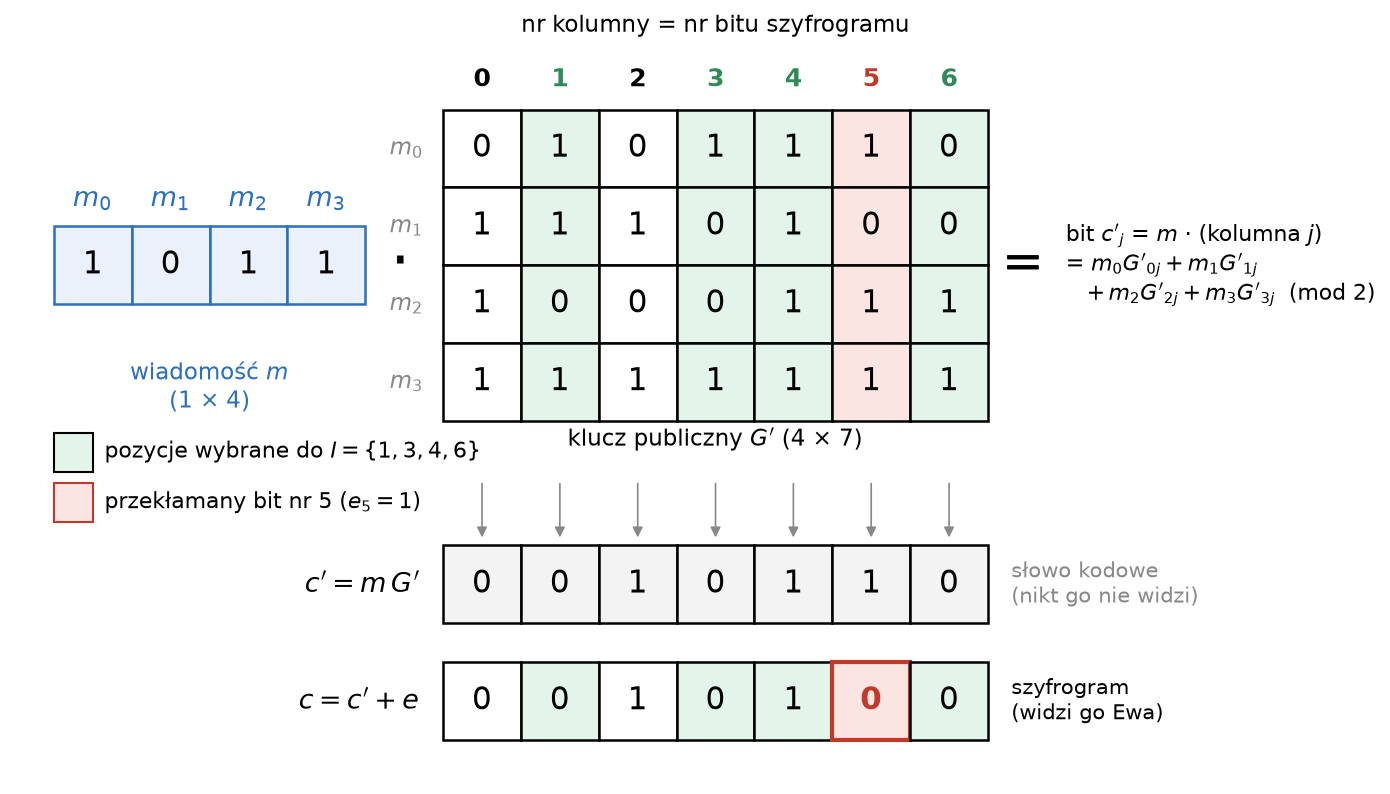

1. Słowo kodowe to $c' = (0, 0, 1, 0, 1, 1, 0)$.
2. Szyfrowanie dodaje błąd $e = (0, 0, 0, 0, 0, 1, 0)$ $\rightarrow$ Ewa widzi szyfrogram $c = (0, 0, 1, 0, 1, \mathbf{0}, 0)$.
3. Ewa może ułożyć **7 równań z 4 niewiadomymi** czyli teoretycznie łatwo rozwiazywalne
4. Niestety **jedno równanie** jest popsute: lewa strona powinna dać 1, a w szyfrogramie jest 0.
5. Ewa **nie zna prawidłowej postaci równań po lewej stronie**; zna prawa stronę i współczynniki macierzy.
6. Ewa wybiera niektóre równania (tzw. **zbiór informacyjny**) i rozwazuje np. Gausem
7. Jeśli wybierze dobrze pozna bity wiadomości (**Sukces**)
8. Jeśli wybierze źle musi spróbować innego wyboru. 


Atak ISD **dekoduje zatem kod publiczny „na ślepo”**. Najprostszy z nich to **algorytm Prange'a** (1962):

1. Wybierz losowo $k$ spośród $n$ pozycji szyfrogramu.
2. **Załóż**, że na tych pozycjach **nie ma błędów**.
3. Wtedy na tych pozycjach $c$ jest zgodne z $m G'$, więc $m$ można wyznaczyć, rozwiązując układ $k$ równań z $k$ niewiadomymi.
4. Sprawdź: jeśli $m G'$ różni się od $c$ na co najwyżej $t$ pozycjach — sukces. W przeciwnym razie wróć do kroku 1.

Strzał jest trafny, gdy wszystkie $t$ błędów leży poza wybranymi $k$ pozycjami. Prawdopodobieństwo tego zdarzenia wynosi
$$ p_{\text{sukcesu}} = \frac{\binom{n-t}{k}}{\binom{n}{k}} , $$
więc średnio potrzeba ok. $1 / p_{\text{sukcesu}}$ prób.


In [ ]:
# Najpierw wygenerujmy na nowo klucze obu kryptosystemów na kodzie Hamminga (funkcje z części II):
pub,   priv   = mceliece_generuj_klucze(G, 1)        # McEliece na kodzie Hamminga (7, 4)
print("klucz publiczny McEliece'a G':");    print(pub[0])


## Zadanie 
Zaimplementuj atak Pranga dla kryptosystemu McEliece z kodem (7,4)-kod Hamminga i kodem Goppa (dla ataku ISD w gruncie rzeczy jaki to kod nie ma znaczenia). 

In [ ]:
def atak_prange(c, G_pub, t, max_prob=100000):
    k, n = G_pub.dimensions()
    #TODO zaimplementuj prosty atak Pranga

    return broken_message

p_sukcesu = binomial(n - t, k) / binomial(n, k)
print(f"prawdopodobieństwo trafienia w jednej próbie: {float(p_sukcesu):.4f}  (średnio ok. {float(1/p_sukcesu):.0f} prób)")

m_tajna = tekst_na_bity("AGH!", k)
c = mceliece_szyfruj(m_tajna, pub_G)
start = time.time()
x, proby = atak_prange(c, G_pub, t)
print(f"Ewa odczytała: {bity_na_tekst(x)!r}  po {proby} próbach, w {time.time() - start:.2f} s")

In [ ]:
parametry = [("nasz przykład",   6,   64,   5),
             ("",                8,  256,  10),
             ("",               10, 1024,  30),
             ("mceliece348864", 12, 3488,  64),
             ("mceliece8192128",13, 8192, 128)]
print("                 |  m |    n |    k |   t | log2(liczba prób Prange'a) | klucz publiczny")
print("-----------------+----+------+------+-----+----------------------------+----------------")
for nazwa, mm, n_, t_ in parametry:
    k_ = n_ - mm * t_
    log_prob = float(RealField(200)(binomial(n_, k_) / binomial(n_ - t_, k_)).log2())
    print(f"{nazwa:16} | {mm:2} | {n_:4} | {k_:4} | {t_:3} | {log_prob:26.1f} | "
          f"{k_ * (n_ - k_) // 8:>9,} B")

Dla `mceliece348864` atak Prange'a wymaga ok. $2^{143}$ prób. Współczesne, ulepszone warianty ISD (Stern, Dumer, May–Meurer–Thomae, Becker–Joux–May–Meurer) obniżają ten koszt tylko nieznacznie, a komputer kwantowy (algorytm Grovera) daje co najwyżej przyspieszenie „pierwiastkowe”, które kompensuje się większymi parametrami.